In [1]:
## 1. Preparación de datos y EDA histórico

In [3]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from functools import lru_cache
import itertools, time

SEED=42
CARPETA=Path('.')
SALIDAS=CARPETA/'resultados_dimension2'
SALIDAS.mkdir(exist_ok=True)
ARCHIVOS=['delivery_events','facilities','loads','routes','trips','trucks']
# En Colab, ejecutar solo si aún no se han cargado los archivos:
faltantes=[x+'.csv' for x in ARCHIVOS if not (CARPETA/(x+'.csv')).exists()]
if faltantes:
    try:
        from google.colab import files
        print('Sube los seis CSV. Faltan:', faltantes)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Archivos faltantes: {faltantes}. Colócalos junto al notebook.')
tablas={x:pd.read_csv(CARPETA/(x+'.csv')) for x in ARCHIVOS}
delivery_events,facilities,loads,routes,trips,trucks=[tablas[x] for x in ARCHIVOS]
sns.set_theme(style='whitegrid');plt.rcParams['figure.dpi']=110
for nombre,t in tablas.items():print(f'{nombre}: {t.shape[0]:,} filas × {t.shape[1]} columnas')

delivery_events: 170,820 filas × 11 columnas
facilities: 50 filas × 9 columnas
loads: 85,410 filas × 12 columnas
routes: 58 filas × 9 columnas
trips: 85,410 filas × 12 columnas
trucks: 120 filas × 11 columnas


In [4]:
# PASO A: Unir 'trips' con 'delivery_events' usando 'trip_id' y 'load_id'
df_1 = trips.merge(delivery_events, on=['trip_id', 'load_id'], how='inner')

# PASO B: Agregar la información de la carga 'loads' usando 'load_id'
df_2 = df_1.merge(loads, on='load_id', how='left')

# PASO C: Agregar la información de los camiones 'trucks' usando 'truck_id'
df_3 = df_2.merge(trucks, on='truck_id', how='left')

# PASO D: Agregar la información de la ruta 'routes' usando 'route_id'
df_4 = df_3.merge(routes, on='route_id', how='left')

# PASO E: Agregar información del almacén/instalación 'facilities' usando 'facility_id'
df_completo = df_4.merge(facilities, on='facility_id', how='left')

print(f"Dataset consolidado creado con éxito.")
print(f"Total de filas cruzadas: {len(df_completo)} registros.")

Dataset consolidado creado con éxito.
Total de filas cruzadas: 170820 registros.


In [5]:
# 1. Limpieza de inconsistencias (distancias o tiempos <= 0)
df_limpio = df_completo[
    (df_completo['actual_distance_miles'] > 0) &
    (df_completo['actual_duration_hours'] > 0)
].copy()

# 2. Conteo dinámico de la flota disponible (N camiones activos)
camiones_activos = trucks[trucks['status'] == 'Active']['truck_id'].unique()
N_disponibles = len(camiones_activos)

print(f"Registros limpios para análisis: {len(df_limpio)}")
print(f"Camiones activos disponibles hoy (N): {N_disponibles} unidades.")

Registros limpios para análisis: 170820
Camiones activos disponibles hoy (N): 92 unidades.


In [6]:
import pandas as pd
import numpy as np

# Variables clave de la Dimensión 2
variables_eda = [
    'actual_duration_hours',
    'detention_minutes',
    'actual_distance_miles',
    'idle_time_hours'
]

resumen_eda = []

for var in variables_eda:
    col = df_limpio[var].dropna()

    # Extraer el primer valor de la moda
    modes = col.mode()

    if not modes.empty:
        moda_val = float(modes.iloc[0])
    else:
        moda_val = np.nan

    resumen_eda.append({
        'Variable': var,
        'Media': f"{col.mean():.2f}",
        'Moda': f"{moda_val:.2f}" if not np.isnan(moda_val) else "N/A",
        'Desviación Estándar': f"{col.std():.2f}",
        'Mínimo': f"{col.min():.2f}",
        'Máximo': f"{col.max():.2f}"
    })

tabla_eda = pd.DataFrame(resumen_eda)

print("=" * 75)
print("TABLA EDA REQUERIDA PARA EL INFORME (COPIAR A WORD)")
print("=" * 75)
print(tabla_eda.to_string(index=False))

TABLA EDA REQUERIDA PARA EL INFORME (COPIAR A WORD)
             Variable   Media  Moda Desviación Estándar Mínimo  Máximo
actual_duration_hours   25.01  1.60               14.19   1.40   67.80
    detention_minutes   91.54  0.00               68.65   0.00  239.00
actual_distance_miles 1430.27 91.00              801.93  90.00 3391.00
      idle_time_hours    7.01  2.60                2.88   2.00   12.00


/tmp/ipykernel_312/3614189470.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


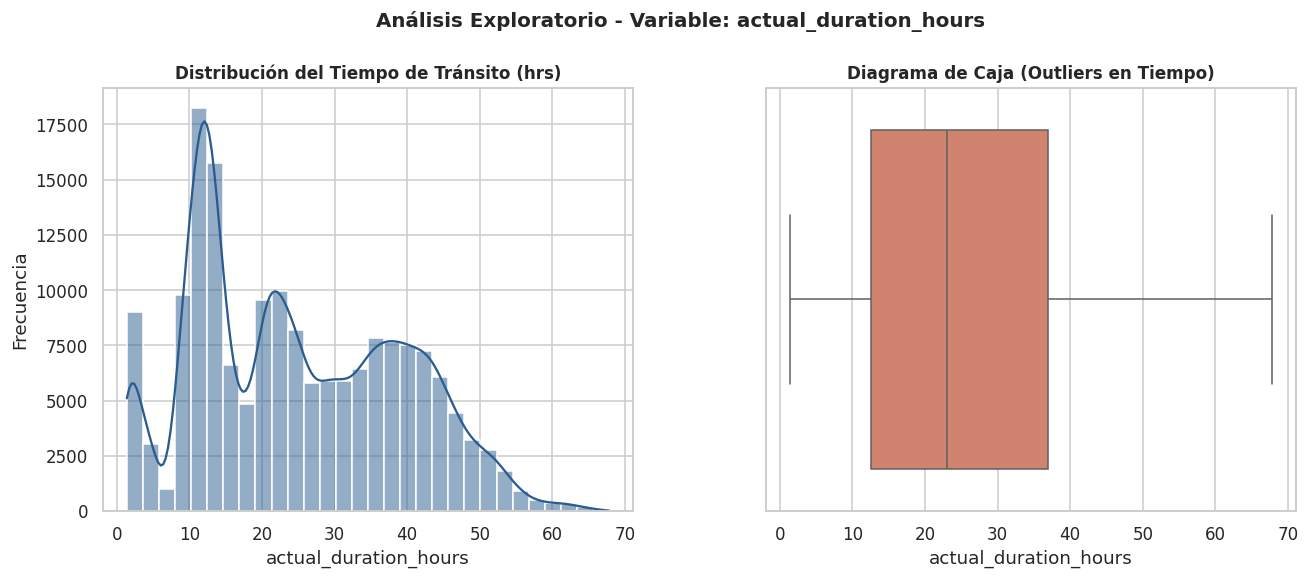

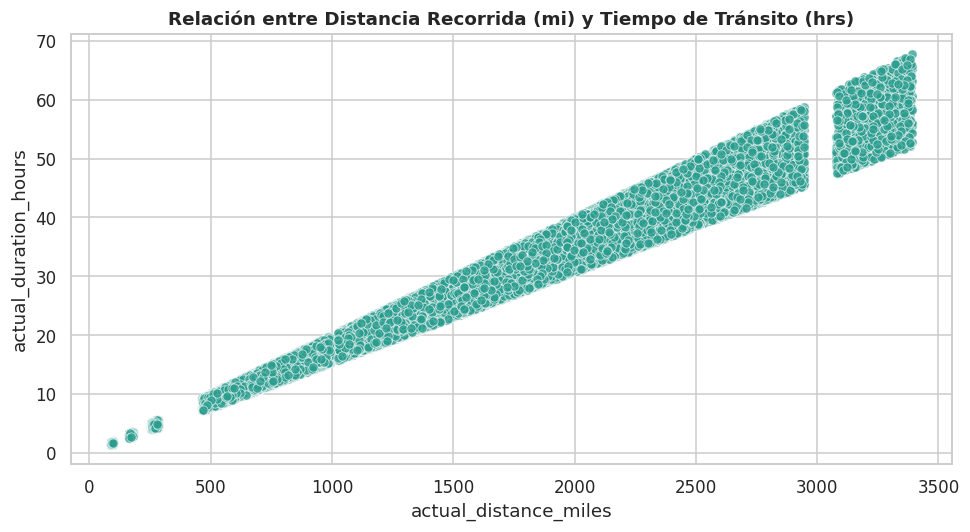

¡Gráficos guardados en el panel de archivos de Colab como PNG!


In [7]:
# FIGURA 1: Histograma + Boxplot de actual_duration_hours
fig, axs = plt.subplots(
    1, 2,
    figsize=(14, 5),
    gridspec_kw={'wspace': 0.25}
)

# Histograma
sns.histplot(
    df_limpio['actual_duration_hours'],
    ax=axs[0],
    kde=True,
    color='#2b5c8f',
    bins=30
)

axs[0].set_title(
    'Distribución del Tiempo de Tránsito (hrs)',
    fontsize=11,
    fontweight='bold'
)

axs[0].set_xlabel('actual_duration_hours')
axs[0].set_ylabel('Frecuencia')

# Boxplot
sns.boxplot(
    x=df_limpio['actual_duration_hours'],
    ax=axs[1],
    color='#e07a5f')

axs[1].set_title(
    'Diagrama de Caja (Outliers en Tiempo)',
    fontsize=11,
    fontweight='bold')

axs[1].set_xlabel('actual_duration_hours')

plt.suptitle(
    'Análisis Exploratorio - Variable: actual_duration_hours',
    fontsize=13,
    fontweight='bold',
    y=1.02)

plt.tight_layout()

plt.savefig(
    'eda_histograma_boxplot_duracion.png',
    dpi=150,
    bbox_inches='tight')

plt.show()

# FIGURA 2: Relación Distancia vs Tiempo de Tránsito
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_limpio,
    x='actual_distance_miles',
    y='actual_duration_hours',
    alpha=0.5,
    color='#2a9d8f')

plt.title(
    'Relación entre Distancia Recorrida (mi) y Tiempo de Tránsito (hrs)',
    fontsize=12,
    fontweight='bold')

plt.xlabel('actual_distance_miles')
plt.ylabel('actual_duration_hours')

plt.tight_layout()

plt.savefig(
    'eda_relacion_distancia_tiempo_serie.png',
    dpi=150,
    bbox_inches='tight')

plt.show()

print("¡Gráficos guardados en el panel de archivos de Colab como PNG!")


## 2. Distribución del peso y utilización de flota

Columnas disponibles:
['trip_id', 'load_id', 'driver_id', 'truck_id', 'trailer_id', 'dispatch_date', 'actual_distance_miles', 'actual_duration_hours', 'fuel_gallons_used', 'average_mpg', 'idle_time_hours', 'trip_status', 'event_id', 'event_type', 'facility_id', 'scheduled_datetime', 'actual_datetime', 'detention_minutes', 'on_time_flag', 'location_city', 'location_state', 'customer_id', 'route_id', 'load_date', 'load_type', 'weight_lbs', 'pieces', 'revenue', 'fuel_surcharge', 'accessorial_charges', 'load_status', 'booking_type', 'unit_number', 'make', 'model_year', 'vin', 'acquisition_date', 'acquisition_mileage', 'fuel_type', 'tank_capacity_gallons', 'status', 'home_terminal', 'origin_city', 'origin_state', 'destination_city', 'destination_state', 'typical_distance_miles', 'base_rate_per_mile', 'fuel_surcharge_rate', 'typical_transit_days', 'facility_name', 'facility_type', 'city', 'state', 'latitude', 'longitude', 'dock_doors', 'operating_hours']

Cantidad de datos: 170820
Peso mínim

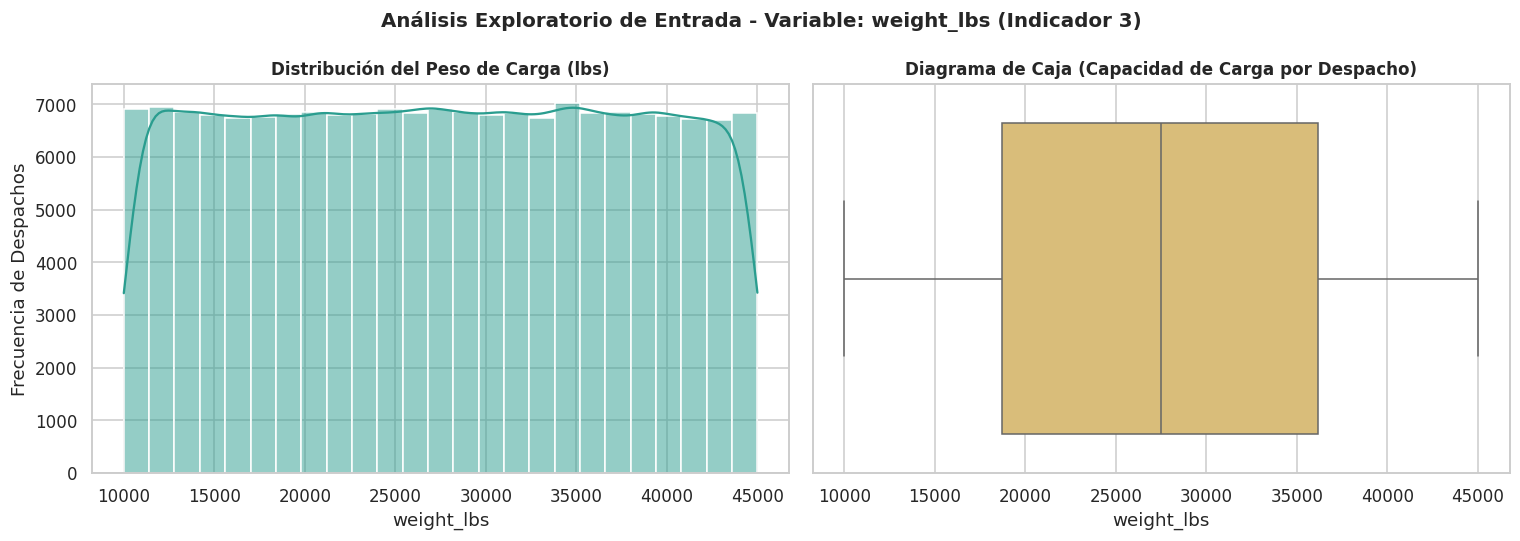


¡Gráfico 'eda_distribucion_peso_carga.png' guardado exitosamente!


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Verificar que la columna exista
print("Columnas disponibles:")
print(df_limpio.columns.tolist())

# Convertir weight_lbs a numérico
df_limpio['weight_lbs'] = pd.to_numeric(
    df_limpio['weight_lbs'],
    errors='coerce'
)

# Eliminar valores vacíos de weight_lbs
peso = df_limpio['weight_lbs'].dropna()

print("\nCantidad de datos:", len(peso))
print("Peso mínimo:", peso.min())
print("Peso máximo:", peso.max())

# Crear figura con 2 gráficos
fig, axs = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# =========================
# 1. HISTOGRAMA
# =========================

sns.histplot(
    data=peso,
    kde=True,
    bins=25,
    color='#2a9d8f',
    ax=axs[0]
)

axs[0].set_title(
    'Distribución del Peso de Carga (lbs)',
    fontsize=11,
    fontweight='bold'
)

axs[0].set_xlabel('weight_lbs')
axs[0].set_ylabel('Frecuencia de Despachos')


# =========================
# 2. BOXPLOT
# =========================

sns.boxplot(
    x=peso,
    color='#e9c46a',
    ax=axs[1]
)

axs[1].set_title(
    'Diagrama de Caja (Capacidad de Carga por Despacho)',
    fontsize=11,
    fontweight='bold'
)

axs[1].set_xlabel('weight_lbs')


# =========================
# TÍTULO GENERAL
# =========================

plt.suptitle(
    'Análisis Exploratorio de Entrada - Variable: weight_lbs (Indicador 3)',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()

# Guardar
plt.savefig(
    'eda_distribucion_peso_carga.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("\n¡Gráfico 'eda_distribucion_peso_carga.png' guardado exitosamente!")


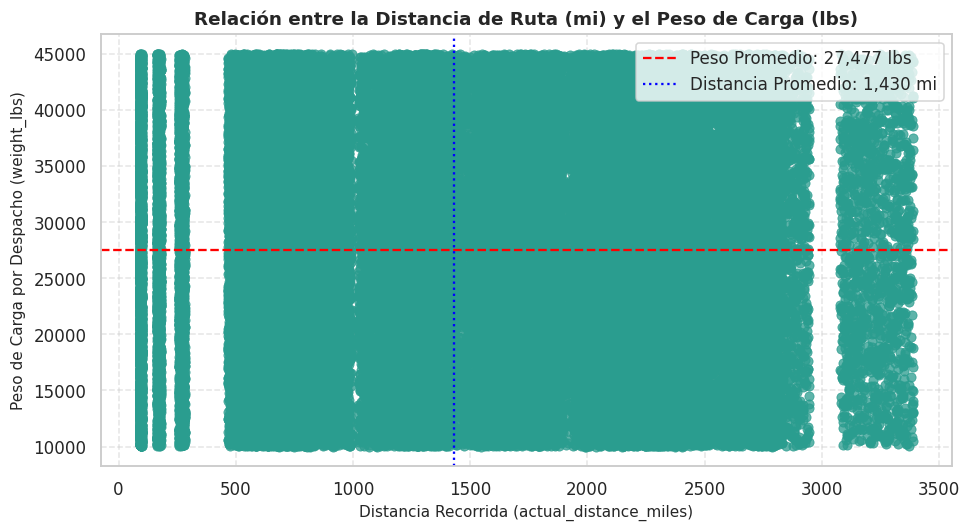

¡Gráfico 'eda_peso_vs_distancia.png' guardado exitosamente!


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_limpio,
    x='actual_distance_miles',
    y='weight_lbs',
    alpha=0.5,
    color='#2a9d8f',
    edgecolor=None
)

plt.axhline(df_limpio['weight_lbs'].mean(), color='red', linestyle='--', label=f"Peso Promedio: {df_limpio['weight_lbs'].mean():,.0f} lbs")
plt.axvline(df_limpio['actual_distance_miles'].mean(), color='blue', linestyle=':', label=f"Distancia Promedio: {df_limpio['actual_distance_miles'].mean():,.0f} mi")

plt.title('Relación entre la Distancia de Ruta (mi) y el Peso de Carga (lbs)', fontsize=12, fontweight='bold')
plt.xlabel('Distancia Recorrida (actual_distance_miles)', fontsize=10)
plt.ylabel('Peso de Carga por Despacho (weight_lbs)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('eda_peso_vs_distancia.png', dpi=150, bbox_inches='tight')
plt.show()

print("¡Gráfico 'eda_peso_vs_distancia.png' guardado exitosamente!")

**Supuesto:** 45,000 lb

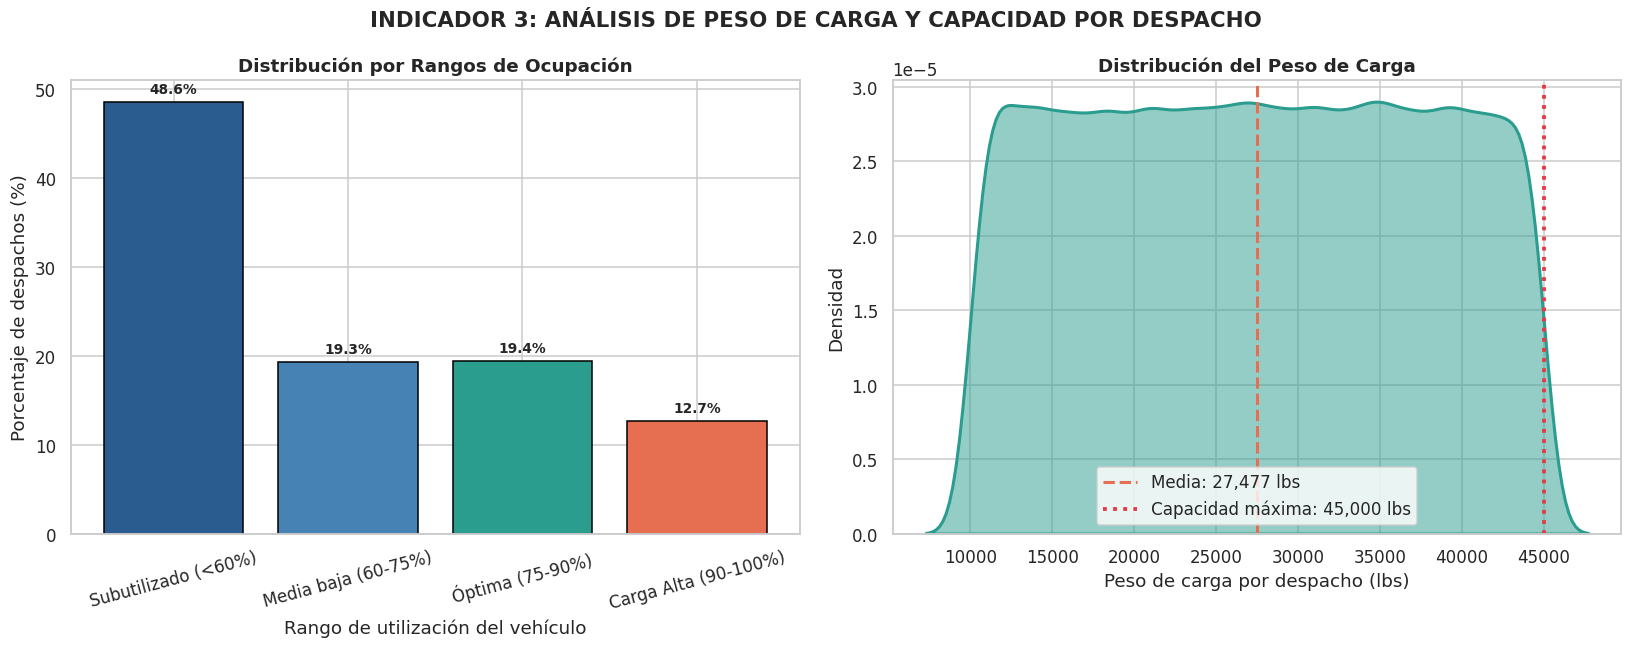

Gráfico generado correctamente.
Archivo guardado como: eda_alternativas_peso_capacidad.png


In [10]:
# ==============================================================================
# INDICADOR 3: PESO DE CARGA Y CAPACIDAD POR DESPACHO
# GRÁFICOS SIN HISTOGRAMA NI BOXPLOT
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

# Capacidad máxima del camión
CAPACIDAD_MAXIMA_LBS = 45000

# ==============================================================================
# 1. CALCULAR UTILIZACIÓN DE CAPACIDAD
# ==============================================================================

df_limpio["cap_pct"] = (
    df_limpio["weight_lbs"] / CAPACIDAD_MAXIMA_LBS
) * 100

# ==============================================================================
# 2. CREAR RANGOS DE OCUPACIÓN
# ==============================================================================

df_limpio["rango_ocupacion"] = pd.cut(
    df_limpio["cap_pct"],
    bins=[0, 60, 75, 90, 100],
    labels=[
        "Subutilizado (<60%)",
        "Media baja (60-75%)",
        "Óptima (75-90%)",
        "Carga Alta (90-100%)"
    ],
    include_lowest=True
)

# ==============================================================================
# 3. CREAR FIGURA
# ==============================================================================

fig, axs = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

# ==============================================================================
# GRÁFICO 1: BARRAS POR RANGO DE OCUPACIÓN
# ==============================================================================

orden = [
    "Subutilizado (<60%)",
    "Media baja (60-75%)",
    "Óptima (75-90%)",
    "Carga Alta (90-100%)"
]

rango_counts = (
    df_limpio["rango_ocupacion"]
    .value_counts(normalize=True)
    .reindex(orden)
    .fillna(0)
    * 100
)

colores = [
    "#2b5c8f",
    "#4682b4",
    "#2a9d8f",
    "#e76f51"
]

bars = axs[0].bar(
    rango_counts.index,
    rango_counts.values,
    color=colores,
    edgecolor="black"
)

axs[0].set_title(
    "Distribución por Rangos de Ocupación",
    fontsize=12,
    fontweight="bold"
)

axs[0].set_xlabel(
    "Rango de utilización del vehículo"
)

axs[0].set_ylabel(
    "Porcentaje de despachos (%)"
)

axs[0].tick_params(
    axis="x",
    rotation=15
)

# Valores encima de las barras
for bar in bars:

    altura = bar.get_height()

    axs[0].text(
        bar.get_x() + bar.get_width() / 2,
        altura + 1,
        f"{altura:.1f}%",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# ==============================================================================
# GRÁFICO 2: CURVA DE DENSIDAD
# ==============================================================================

sns.kdeplot(
    data=df_limpio,
    x="weight_lbs",
    ax=axs[1],
    fill=True,
    color="#2a9d8f",
    alpha=0.5,
    linewidth=2
)

# Calcular media
media_peso = df_limpio["weight_lbs"].mean()

# Línea de la media
axs[1].axvline(
    media_peso,
    color="#e76f51",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_peso:,.0f} lbs"
)

# Línea de capacidad máxima
axs[1].axvline(
    CAPACIDAD_MAXIMA_LBS,
    color="#e63946",
    linestyle=":",
    linewidth=2.5,
    label=f"Capacidad máxima: {CAPACIDAD_MAXIMA_LBS:,.0f} lbs"
)

axs[1].set_title(
    "Distribución del Peso de Carga",
    fontsize=12,
    fontweight="bold"
)

axs[1].set_xlabel(
    "Peso de carga por despacho (lbs)"
)

axs[1].set_ylabel(
    "Densidad"
)

axs[1].legend()

# ==============================================================================
# TÍTULO GENERAL
# ==============================================================================

fig.suptitle(
    "INDICADOR 3: ANÁLISIS DE PESO DE CARGA Y CAPACIDAD POR DESPACHO",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ==============================================================================
# GUARDAR
# ==============================================================================

plt.savefig(
    "eda_alternativas_peso_capacidad.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfico generado correctamente.")
print("Archivo guardado como: eda_alternativas_peso_capacidad.png")

## 3. Base de viajes únicos y consistencia geográfica

In [13]:
trips, loads, events, facilities, routes, trucks = [
    tablas[k] for k in [
        'trips', 'loads', 'delivery_events',
        'facilities', 'routes', 'trucks'
    ]
]
assert trips.trip_id.is_unique and loads.load_id.is_unique and routes.route_id.is_unique
assert facilities.facility_id.is_unique
assert events.groupby('trip_id').event_type.agg(lambda s: set(s)=={'Pickup','Delivery'}).all(), 'Existen viajes sin Pickup/Delivery estándar'

pu=(events[events.event_type=='Pickup']
    [['trip_id','facility_id']].rename(columns={'facility_id':'pickup_facility'}))
de=(events[events.event_type=='Delivery']
    [['trip_id','facility_id','scheduled_datetime']]
    .rename(columns={'facility_id':'delivery_facility','scheduled_datetime':'delivery_scheduled'}))
assert pu.trip_id.is_unique and de.trip_id.is_unique

viajes=(trips.merge(loads,on='load_id',validate='one_to_one')
    .merge(routes,on='route_id',validate='many_to_one')
    .merge(pu,on='trip_id',validate='one_to_one')
    .merge(de,on='trip_id',validate='one_to_one'))
geo=facilities.set_index('facility_id')[['latitude','longitude','city','state']]
for etiqueta,col in [('origen','pickup_facility'),('destino','delivery_facility')]:
    for c in ['latitude','longitude']:
        viajes[etiqueta+'_'+c]=viajes[col].map(geo[c])
viajes['dispatch_date']=pd.to_datetime(viajes['dispatch_date'])
viajes['delivery_scheduled']=pd.to_datetime(viajes['delivery_scheduled'])
viajes=viajes.sort_values(['dispatch_date','trip_id']).reset_index(drop=True)
print('Viajes únicos', len(viajes), '| fechas',viajes.dispatch_date.min().date(),viajes.dispatch_date.max().date())
print('Camiones con estado actual Activo (no histórico):',(trucks.status=='Active').sum())
print('Columnas de capacidad en trucks:', [c for c in trucks if 'capac' in c.lower()])
print('Registros EDA:',len(df_limpio),'| viajes únicos:',len(viajes))
if len(viajes)!=len(df_limpio):print('AVISO: EDA y viajes únicos tienen distinto grano; no comparar conteos directamente.')

Viajes únicos 85410 | fechas 2022-01-01 2024-12-31
Camiones con estado actual Activo (no histórico): 92
Columnas de capacidad en trucks: ['tank_capacity_gallons']
Registros EDA: 170820 | viajes únicos: 85410
AVISO: EDA y viajes únicos tienen distinto grano; no comparar conteos directamente.


## 4. Reducción de variables predictoras (5 → 3)

In [14]:
def haversine_miles(lat1,lon1,lat2,lon2):
    r=3958.7613
    a1,a2=np.radians(lat1),np.radians(lat2)
    da=a2-a1; dl=np.radians(lon2)-np.radians(lon1)
    x=np.sin(da/2)**2+np.cos(a1)*np.cos(a2)*np.sin(dl/2)**2
    return 2*r*np.arcsin(np.sqrt(np.clip(x,0,1)))
viajes['distancia_geodesica_millas']=haversine_miles(
    viajes.origen_latitude,viajes.origen_longitude,
    viajes.destino_latitude,viajes.destino_longitude)
FEATURES=['typical_distance_miles','weight_lbs','pieces',
          'typical_transit_days','distancia_geodesica_millas']
OBJETIVO='actual_duration_hours'
model_data=viajes.dropna(subset=FEATURES+[OBJETIVO]).copy()
model_data=model_data[(model_data[OBJETIVO]>0)&(model_data[FEATURES]>=0).all(axis=1)]
# División cronológica evitando utilizar registros futuros para entrenar el pasado.
anos=set(model_data.dispatch_date.dt.year.unique())
if {2022,2023,2024}.issubset(anos):
    train=model_data[model_data.dispatch_date.dt.year==2022].copy()
    val=model_data[model_data.dispatch_date.dt.year==2023].copy()
    test=model_data[model_data.dispatch_date.dt.year==2024].copy()
    print('División temporal: entrenamiento 2022, validación 2023, prueba 2024')
else:
    ordenado=model_data.sort_values(['dispatch_date','trip_id']).reset_index(drop=True)
    # fechas completas: mismo día siempre pertenece al mismo subconjunto
    fechas=ordenado.dispatch_date.dt.normalize().drop_duplicates().sort_values().to_numpy()
    if len(fechas)<5:raise ValueError('Se requieren al menos 5 fechas distintas para división temporal.')
    f1=fechas[max(1,int(.6*len(fechas)))-1]
    f2=fechas[max(2,int(.8*len(fechas)))-1]
    train=ordenado[ordenado.dispatch_date.dt.normalize()<=f1].copy()
    val=ordenado[(ordenado.dispatch_date.dt.normalize()>f1)&(ordenado.dispatch_date.dt.normalize()<=f2)].copy()
    test=ordenado[ordenado.dispatch_date.dt.normalize()>f2].copy()
    print('División por fechas cronológicas: ~60%/20%/20%')
if min(len(train),len(val),len(test))<5:
    raise ValueError('Los subconjuntos de entrenamiento, validación y prueba deben contener al menos 5 viajes cada uno.')
print('Tamaños train/val/test:',len(train),len(val),len(test))

def nuevo_rf():
    return RandomForestRegressor(n_estimators=55,max_depth=10,
                                 min_samples_leaf=3,random_state=SEED,n_jobs=-1)
rf_select=nuevo_rf();rf_select.fit(train[FEATURES],train[OBJETIVO])
valid_pred=rf_select.predict(val[FEATURES])
print('MAE validación inicial:',round(mean_absolute_error(val[OBJETIVO],valid_pred),3),'horas')
# Importancia calculada sobre validación, antes de mirar el año de prueba
val_importancia=val.sample(n=min(1500,len(val)),random_state=SEED)
pi=permutation_importance(rf_select,val_importancia[FEATURES],val_importancia[OBJETIVO],
                          scoring='neg_mean_absolute_error',
                          n_repeats=3,random_state=SEED,n_jobs=1)
importancia=(pd.DataFrame({'variable':FEATURES,'aumento_MAE_al_permutar':pi.importances_mean})
            .sort_values('aumento_MAE_al_permutar',ascending=False))
display(importancia)
# Regla fijada antes de evaluar el test: elegir tres variables con mayor importancia.
FEATURES_REDUCIDAS=importancia.head(3).variable.tolist()
print('Selección (5 -> 3):',FEATURES_REDUCIDAS)

División temporal: entrenamiento 2022, validación 2023, prueba 2024
Tamaños train/val/test: 28589 28165 28656
MAE validación inicial: 1.729 horas


,variable,aumento_MAE_al_permutar
0,typical_distance_miles,13.739735
1,weight_lbs,0.009459
4,distancia_geodesica_millas,0.005955
3,typical_transit_days,0.005600
2,pieces,0.003398


Selección (5 -> 3): ['typical_distance_miles', 'weight_lbs', 'distancia_geodesica_millas']


,modelo,n_variables,MAE_h,RMSE_h,R2,entrenamiento_s
0,Completo (5 variables),5,1.7128,2.3231,0.9733,7.8117
1,Reducido (3 variables),3,1.7132,2.3248,0.9733,5.1336


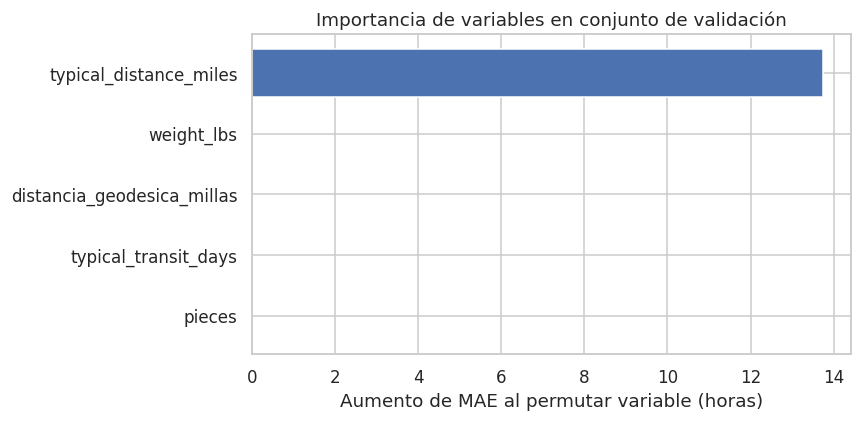

In [15]:
desarrollo=pd.concat([train,val]).sort_values('dispatch_date')
resultados=[]; modelos={}
for etiqueta,campos in [('Completo (5 variables)',FEATURES),
                        ('Reducido (3 variables)',FEATURES_REDUCIDAS)]:
    m=nuevo_rf()
    inicio=time.perf_counter()
    m.fit(desarrollo[campos],desarrollo[OBJETIVO])
    tiempo=time.perf_counter()-inicio
    pred=m.predict(test[campos])
    resultados.append({'modelo':etiqueta,'n_variables':len(campos),
        'MAE_h':mean_absolute_error(test[OBJETIVO],pred),
        'RMSE_h':np.sqrt(mean_squared_error(test[OBJETIVO],pred)),
        'R2':r2_score(test[OBJETIVO],pred),'entrenamiento_s':tiempo})
    modelos[etiqueta]=m
comparacion_ml=pd.DataFrame(resultados)
display(comparacion_ml.round(4))
comparacion_ml.to_csv(SALIDAS/'comparacion_reduccion.csv',index=False)
importancia.to_csv(SALIDAS/'importancia_variables.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.barh(importancia.variable[::-1],importancia.aumento_MAE_al_permutar[::-1]);
ax.set_xlabel('Aumento de MAE al permutar variable (horas)');ax.set_title('Importancia de variables en conjunto de validación');plt.tight_layout()
fig.savefig(SALIDAS/'reduccion_variables.png',dpi=160);plt.show()

## 5. Selección de escenario piloto de entregas

In [16]:
CAPACIDAD_LB=45000  # SUPUESTO: sustituir por la capacidad validada para cada vehículo
N_PEDIDOS=6
VELOCIDAD_MPH=50.0  # supuesto para convertir distancia geodesica en tiempo ilustrativo
SERVICIO_H_POR_PARADA=0.5  # supuesto

def factible_n_camiones(pesos,n):
    # Comprobación exacta de factibilidad para el piloto de seis pedidos
    por_vehiculo=[0]*n
    def rec(i):
        if i==len(pesos):return True
        usados=set()
        for v in range(n):
            if por_vehiculo[v] in usados:continue
            usados.add(por_vehiculo[v])
            if por_vehiculo[v]+pesos[i]<=CAPACIDAD_LB:
                por_vehiculo[v]+=pesos[i]
                if rec(i+1):return True
                por_vehiculo[v]-=pesos[i]
        return False
    return rec(0)

escenario=None
for (fecha,origen),grupo in viajes.groupby(['dispatch_date','pickup_facility'],sort=True):
    if len(grupo)<N_PEDIDOS:continue
    candidato=grupo.sort_values(['weight_lbs','trip_id']).head(N_PEDIDOS).copy()
    pesos=candidato.weight_lbs.astype(int).tolist()
    if candidato.delivery_facility.nunique()!=N_PEDIDOS:continue
    # Evitar destinos geográficamente coincidentes con el origen o entre sí
    coords_dest=list(zip(candidato.destino_latitude.round(4),candidato.destino_longitude.round(4)))
    coord_origen=(round(float(candidato.origen_latitude.iloc[0]),4),round(float(candidato.origen_longitude.iloc[0]),4))
    if len(set(coords_dest))!=N_PEDIDOS or coord_origen in coords_dest:continue
    if sum(pesos)>3*CAPACIDAD_LB:continue
    if factible_n_camiones(pesos,3):
        escenario=candidato.sort_values('delivery_scheduled').reset_index(drop=True)
        FECHA=fecha; ORIGEN=origen
        break
if escenario is None:
    raise ValueError('No hay seis destinos distintos, origen común y fecha común con capacidad suficiente para 3 camiones. Revisar datos o hipótesis; NO se inventan pedidos.')
assert len(escenario)==N_PEDIDOS
print('Escenario fecha:',FECHA.date(),'| origen:',ORIGEN,'| carga total (lb):',escenario.weight_lbs.sum())
display(escenario[['trip_id','load_id','pickup_facility','delivery_facility','weight_lbs','delivery_scheduled']])
escenario_cols=['trip_id','load_id','pickup_facility','delivery_facility','weight_lbs','delivery_scheduled']
escenario_csv=escenario[escenario_cols].copy()
escenario_csv.to_csv(SALIDAS/'escenario_historico.csv',index=False)

Escenario fecha: 2022-05-16 | origen: FAC00003 | carga total (lb): 105569


,trip_id,load_id,pickup_facility,delivery_facility,weight_lbs,delivery_scheduled
0,TRIP00010597,LOAD00010597,FAC00003,FAC00050,22122,2022-05-16 18:47:44.370654
1,TRIP00010580,LOAD00010580,FAC00003,FAC00038,21890,2022-05-16 21:33:04.630029
2,TRIP00010576,LOAD00010576,FAC00003,FAC00046,14462,2022-05-16 23:13:00.277420
3,TRIP00010607,LOAD00010607,FAC00003,FAC00006,10765,2022-05-16 23:30:27.218479
4,TRIP00010610,LOAD00010610,FAC00003,FAC00004,16808,2022-05-17 10:09:54.716273
5,TRIP00010632,LOAD00010632,FAC00003,FAC00029,19522,2022-05-17 11:18:59.075355


## 6. Agrupamiento geográfico exploratorio (opcional, no equivale a ruteo)

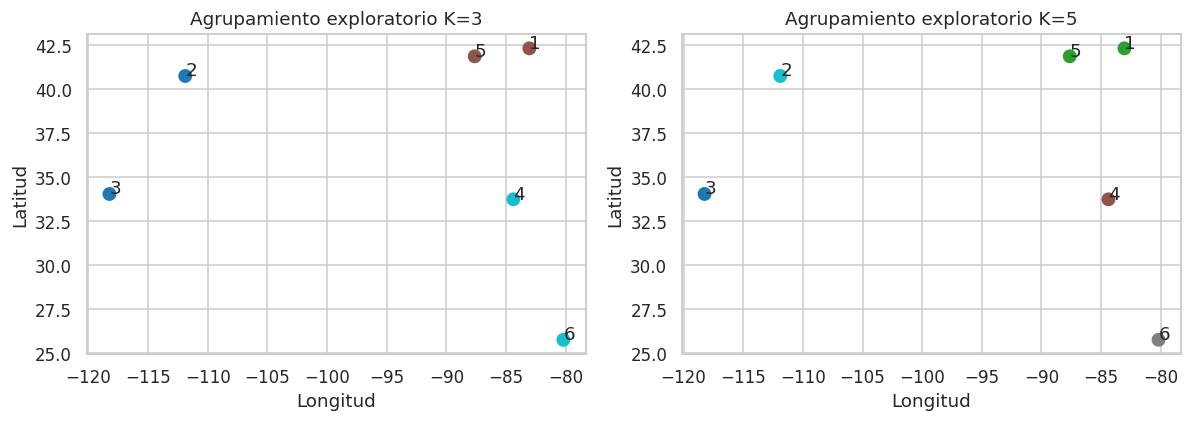

In [17]:
pts=escenario[['destino_latitude','destino_longitude']].to_numpy()
X_geo=StandardScaler().fit_transform(pts)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,n in zip(axs,[3,5]):
    grupos=KMeans(n_clusters=n,random_state=SEED,n_init=10).fit_predict(X_geo)
    ax.scatter(escenario.destino_longitude,escenario.destino_latitude,c=grupos,cmap='tab10',s=65)
    for k,row in escenario.iterrows():ax.annotate(str(k+1),(row.destino_longitude,row.destino_latitude))
    ax.set(title=f'Agrupamiento exploratorio K={n}',xlabel='Longitud',ylabel='Latitud')
fig.tight_layout();fig.savefig(SALIDAS/'clusters_exploratorios.png',dpi=160);plt.show()

## 7. Ruteo optimizado y secuencia de visitas para 3 y 5 camiones

In [18]:
ids=[ORIGEN]+escenario.delivery_facility.tolist()
lat=geo.loc[ids,'latitude'].to_numpy(dtype=float)
lon=geo.loc[ids,'longitude'].to_numpy(dtype=float)
matriz=haversine_miles(lat[:,None],lon[:,None],lat[None,:],lon[None,:])
pesos=escenario.weight_lbs.astype(int).tolist();m=len(pesos)

def distancia_recorrido(visitas):
    sec=[0]+[v+1 for v in visitas]+[0]
    return sum(float(matriz[a,b]) for a,b in zip(sec[:-1],sec[1:]))

# Mejor orden de visitas para cada conjunto posible de entregas (n <= 6)
mejor_subconjunto={}; total_peso={}
for mask in range(1,1<<m):
    conjunto=tuple(i for i in range(m) if (mask>>i)&1)
    total_peso[mask]=sum(pesos[i] for i in conjunto)
    if total_peso[mask]>CAPACIDAD_LB:continue
    orden=min(itertools.permutations(conjunto),key=distancia_recorrido)
    mejor_subconjunto[mask]=(distancia_recorrido(orden),list(orden))

@lru_cache(None)
def solucion_exacta(mask, vehiculos):
    if vehiculos==0:
        return (0.0,()) if mask==0 else (float('inf'),())
    if mask.bit_count()<vehiculos:return float('inf'),()
    best=(float('inf'),())
    sub=mask
    while sub:
        if sub in mejor_subconjunto:
            costo,orden=mejor_subconjunto[sub]
            previo,rutas=solucion_exacta(mask^sub,vehiculos-1)
            if costo+previo<best[0]:best=(costo+previo,rutas+(tuple(orden),))
        sub=(sub-1)&mask
    return best

def referencia_greedy(n):
    # Referencia por orden programado con búsqueda de factibilidad;
    # no minimiza distancia. Backtracking evita falso "infactible"
    # de un primer ajuste demasiado ingenuo.
    cargas=[0]*n;rutas=[[] for _ in range(n)]
    def rec(i):
        if i==m:
            return all(len(r)>0 for r in rutas)
        vistos=set()
        for j in sorted(range(n),key=lambda j:(cargas[j],j)):
            if cargas[j] in vistos:continue
            vistos.add(cargas[j])
            if cargas[j]+pesos[i]<=CAPACIDAD_LB:
                cargas[j]+=pesos[i];rutas[j].append(i)
                if rec(i+1):return True
                rutas[j].pop();cargas[j]-=pesos[i]
        return False
    return rutas if rec(0) else None

rutas_opt={}; rutas_base={}; filas=[]; detalle=[]
for n in [3,5]:
    costo,rutas=solucion_exacta((1<<m)-1,n)
    if not np.isfinite(costo):raise RuntimeError(f'Escenario infactible para N={n}')
    rutas_opt[n]=[list(r) for r in rutas]
    rb=referencia_greedy(n)
    if rb is None:raise RuntimeError(f'No hay asignación inicial factible para N={n}')
    rutas_base[n]=rb
    total_ref=sum(distancia_recorrido(r) for r in rb)
    assert all(r for r in rb) and all(r for r in rutas), 'Se exigen N rutas no vacías'
    total_opt=sum(distancia_recorrido(r) for r in rutas)
    max_ref=max(distancia_recorrido(r)/VELOCIDAD_MPH+len(r)*SERVICIO_H_POR_PARADA for r in rb)
    max_opt=max(distancia_recorrido(r)/VELOCIDAD_MPH+len(r)*SERVICIO_H_POR_PARADA for r in rutas)
    filas.append({'N_camiones':n,'n_entregas':m,'peso_total_lb':sum(pesos),
        'distancia_referencia_millas_geodesicas':total_ref,
        'distancia_optimizada_millas_geodesicas':total_opt,
        'reduccion_distancia_pct':100*(total_ref-total_opt)/total_ref,
        'makespan_referencia_h_estimadas':max_ref,
        'makespan_optimizado_h_estimadas':max_opt,
        'variacion_makespan_pct':100*(max_ref-max_opt)/max_ref})
    for modalidad,rset in [('Referencia',rb),('Optimizada',rutas)]:
        for j,r in enumerate(rset,1):
            detalle.append({'N_camiones':n,'escenario':modalidad,'vehiculo':f'Camion_{j}',
                'secuencia':ORIGEN+' → '+' → '.join(escenario.delivery_facility.iloc[i] for i in r)+' → '+ORIGEN,
                'peso_lb':sum(pesos[i] for i in r),'capacidad_lb_supuesta':CAPACIDAD_LB,
                'distancia_millas_geodesicas':distancia_recorrido(r),
                'tiempo_h_estimado':distancia_recorrido(r)/VELOCIDAD_MPH+len(r)*SERVICIO_H_POR_PARADA})
comparacion_rutas=pd.DataFrame(filas)
detalle_rutas=pd.DataFrame(detalle)
display(comparacion_rutas.round(3));display(detalle_rutas.round(2))
comparacion_rutas.to_csv(SALIDAS/'comparacion_rutas.csv',index=False)
detalle_rutas.to_csv(SALIDAS/'secuencias_por_camion.csv',index=False)
assert (detalle_rutas.peso_lb<=CAPACIDAD_LB).all()
assert all(sum(len(r) for r in rutas_opt[n])==m for n in [3,5])
print('Nota: la optimización minimiza distancia total; el tiempo máximo por vehículo (makespan) no necesariamente mejora.')


,N_camiones,n_entregas,peso_total_lb,distancia_referencia_millas_geodesicas,distancia_optimizada_millas_geodesicas,reduccion_distancia_pct,makespan_referencia_h_estimadas,makespan_optimizado_h_estimadas,variacion_makespan_pct
0,3,6,105569,10158.562,7235.556,28.774,86.478,89.367,-3.340
1,5,6,105569,11350.012,8365.939,26.291,85.101,89.367,-5.013


,N_camiones,escenario,vehiculo,secuencia,peso_lb,capacidad_lb_supuesta,distancia_millas_geodesicas,tiempo_h_estimado
0,3,Referencia,Camion_1,FAC00003 → FAC00050 → FAC00029 → FAC00003,41644,45000,2316.35,47.33
1,3,Referencia,Camion_2,FAC00003 → FAC00038 → FAC00004 → FAC00003,38698,45000,3568.31,72.37
2,3,Referencia,Camion_3,FAC00003 → FAC00046 → FAC00006 → FAC00003,25227,45000,4273.91,86.48
3,3,Optimizada,Camion_1,FAC00003 → FAC00038 → FAC00046 → FAC00003,36352,45000,4418.34,89.37
4,3,Optimizada,Camion_2,FAC00003 → FAC00050 → FAC00004 → FAC00003,38930,45000,1329.47,27.59
5,3,Optimizada,Camion_3,FAC00003 → FAC00006 → FAC00029 → FAC00003,30287,45000,1487.75,30.75
6,5,Referencia,Camion_1,FAC00003 → FAC00050 → FAC00003,22122,45000,1009.88,20.70
7,5,Referencia,Camion_2,FAC00003 → FAC00038 → FAC00003,21890,45000,3447.36,69.45
8,5,Referencia,Camion_3,FAC00003 → FAC00046 → FAC00003,14462,45000,4230.03,85.10
9,5,Referencia,Camion_4,FAC00003 → FAC00006 → FAC00029 → FAC00003,30287,45000,1487.75,30.75


Nota: la optimización minimiza distancia total; el tiempo máximo por vehículo (makespan) no necesariamente mejora.


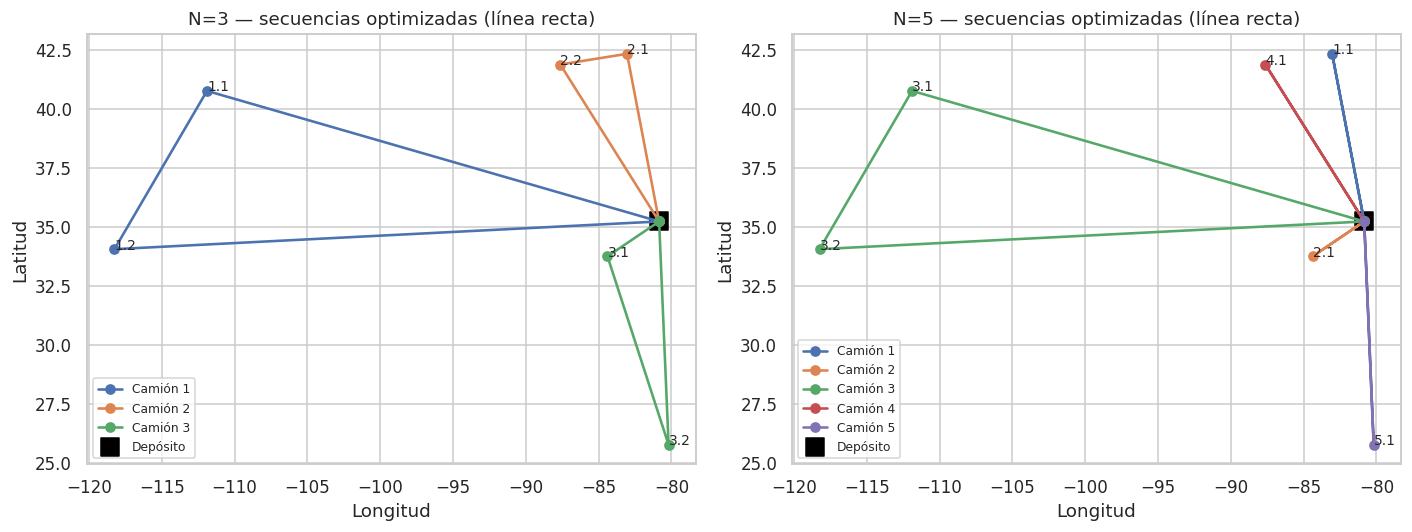

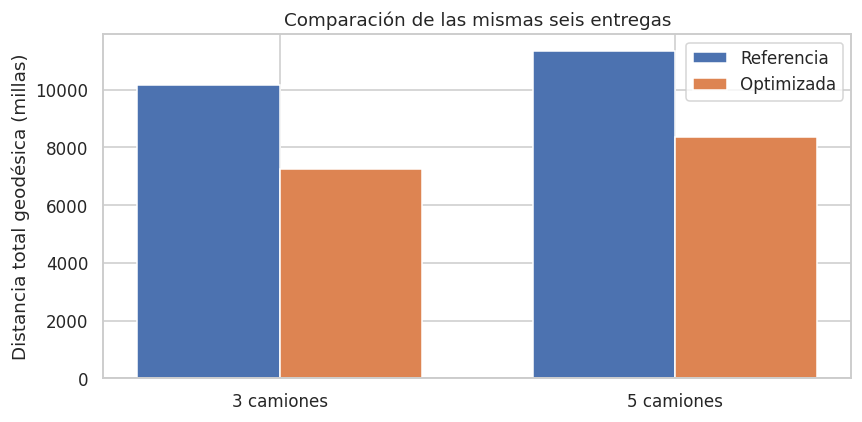

In [19]:
# Mapa de segmentos geodésicos (NO son trazados de carretera)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,n in zip(axs,[3,5]):
    for j,r in enumerate(rutas_opt[n],1):
        sec=[0]+[i+1 for i in r]+[0]
        ax.plot(lon[sec],lat[sec],'-o',linewidth=1.7,label=f'Camión {j}')
        for orden,idx in enumerate(r,1):
            ax.annotate(f'{j}.{orden}',(lon[idx+1],lat[idx+1]),fontsize=9)
    ax.scatter([lon[0]],[lat[0]],marker='s',s=140,c='black',label='Depósito')
    ax.set(xlabel='Longitud',ylabel='Latitud',title=f'N={n} — secuencias optimizadas (línea recta)')
    ax.legend(loc='best',fontsize=8)
fig.tight_layout();fig.savefig(SALIDAS/'rutas_n3_n5.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
pos=np.arange(len(comparacion_rutas));width=.36
ax.bar(pos-width/2,comparacion_rutas.distancia_referencia_millas_geodesicas,width,label='Referencia')
ax.bar(pos+width/2,comparacion_rutas.distancia_optimizada_millas_geodesicas,width,label='Optimizada')
ax.set_xticks(pos,labels=['3 camiones','5 camiones']);ax.set_ylabel('Distancia total geodésica (millas)')
ax.set_title('Comparación de las mismas seis entregas');ax.legend()
fig.tight_layout();fig.savefig(SALIDAS/'comparacion_distancia.png',dpi=160);plt.show()

## 8. Verificaciones y resumen exportable para el informe

In [20]:
# Controles de consistencia de la comparación de los mismos pedidos
for n_camiones in (3,5):
    optimizadas=rutas_opt[n_camiones]
    referencias=rutas_base[n_camiones]
    assert len(optimizadas)==n_camiones and len(referencias)==n_camiones
    assert sorted(i for ruta in optimizadas for i in ruta)==list(range(m))
    assert sorted(i for ruta in referencias for i in ruta)==list(range(m))
    assert all(sum(pesos[i] for i in r)<=CAPACIDAD_LB for r in optimizadas+referencias)
    ref=sum(distancia_recorrido(r) for r in referencias)
    opt=sum(distancia_recorrido(r) for r in optimizadas)
    assert opt<=ref+1e-6

print('RESUMEN A: REDUCCIÓN DE DIMENSIONES')
display(comparacion_ml.round(3))
print('RESUMEN B: RUTEO GEODÉSICO PARA LOS MISMOS 6 PEDIDOS')
display(comparacion_rutas.round(3))
print('RESUMEN C: SECUENCIAS Y CARGAS POR CAMIÓN')
display(detalle_rutas.round(2))
print('Archivos de salida en:',SALIDAS.resolve())
print('ATENCIÓN: ningún ahorro es observado en campo; se trata de una comparación dentro del piloto.')

RESUMEN A: REDUCCIÓN DE DIMENSIONES


,modelo,n_variables,MAE_h,RMSE_h,R2,entrenamiento_s
0,Completo (5 variables),5,1.713,2.323,0.973,7.812
1,Reducido (3 variables),3,1.713,2.325,0.973,5.134


RESUMEN B: RUTEO GEODÉSICO PARA LOS MISMOS 6 PEDIDOS


,N_camiones,n_entregas,peso_total_lb,distancia_referencia_millas_geodesicas,distancia_optimizada_millas_geodesicas,reduccion_distancia_pct,makespan_referencia_h_estimadas,makespan_optimizado_h_estimadas,variacion_makespan_pct
0,3,6,105569,10158.562,7235.556,28.774,86.478,89.367,-3.340
1,5,6,105569,11350.012,8365.939,26.291,85.101,89.367,-5.013


RESUMEN C: SECUENCIAS Y CARGAS POR CAMIÓN


,N_camiones,escenario,vehiculo,secuencia,peso_lb,capacidad_lb_supuesta,distancia_millas_geodesicas,tiempo_h_estimado
0,3,Referencia,Camion_1,FAC00003 → FAC00050 → FAC00029 → FAC00003,41644,45000,2316.35,47.33
1,3,Referencia,Camion_2,FAC00003 → FAC00038 → FAC00004 → FAC00003,38698,45000,3568.31,72.37
2,3,Referencia,Camion_3,FAC00003 → FAC00046 → FAC00006 → FAC00003,25227,45000,4273.91,86.48
3,3,Optimizada,Camion_1,FAC00003 → FAC00038 → FAC00046 → FAC00003,36352,45000,4418.34,89.37
4,3,Optimizada,Camion_2,FAC00003 → FAC00050 → FAC00004 → FAC00003,38930,45000,1329.47,27.59
5,3,Optimizada,Camion_3,FAC00003 → FAC00006 → FAC00029 → FAC00003,30287,45000,1487.75,30.75
6,5,Referencia,Camion_1,FAC00003 → FAC00050 → FAC00003,22122,45000,1009.88,20.70
7,5,Referencia,Camion_2,FAC00003 → FAC00038 → FAC00003,21890,45000,3447.36,69.45
8,5,Referencia,Camion_3,FAC00003 → FAC00046 → FAC00003,14462,45000,4230.03,85.10
9,5,Referencia,Camion_4,FAC00003 → FAC00006 → FAC00029 → FAC00003,30287,45000,1487.75,30.75


Archivos de salida en: /content/resultados_dimension2
ATENCIÓN: ningún ahorro es observado en campo; se trata de una comparación dentro del piloto.
